# Python Programs – Complete Explanation and Code

**Combined practical study notebook**

This notebook contains all 11 uploaded programs. Each topic includes:
- Purpose and concept
- Important terms and formulas
- Step-by-step explanation
- Original uploaded Python program in an executable code cell
- A short interpretation or study note

Run the code cells in order. Some programs require packages such as `numpy`, `matplotlib`, `scipy`, and `pgmpy`.

## Installation (if required)

```python
%pip install numpy matplotlib scipy pgmpy
```

For graph plots, run the notebook in Jupyter Notebook, JupyterLab, or Google Colab.

## Contents

1. Breadth-First Search (BFS)
2. Depth-First Search (DFS)
3. Uniform Cost Search (UCS)
4. A* Search
5. Bernoulli Distribution
6. Binomial Distribution
7. Continuous Uniform Distribution
8. Bayesian Network – Traffic Example
9. Bayesian Inference – Burglary, Earthquake and Alarm
10. Enumeration Algorithm
11. Hidden Markov Model – Forward and Backward

## 1. Breadth-First Search (BFS)

**Purpose:** BFS explores a graph level by level. It visits nearer nodes before deeper nodes.

**Key concepts**
- **Queue (FIFO):** First In, First Out. `pop(0)` removes the oldest path.
- **Frontier:** Paths waiting to be explored.
- **Visited:** Nodes already expanded.
- With equal edge costs, BFS finds a path with the fewest edges.

**Step-by-step**
1. `graph` stores each node and its neighbours.
2. `queue = [[start]]` begins with the path `['A']`.
3. The oldest path is removed using `pop(0)`.
4. `path[-1]` identifies the current node.
5. If the node is the goal, the path and its edge count are printed.
6. Otherwise, paths extended by each unvisited neighbour are added to the queue.
7. `len(path) - 1` counts the edges in the path.

> **Important note:** BFS is suitable for finding a minimum-edge path when all edges have equal cost.

In [ ]:
graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'F', 'G'],
    'D': ['B'],
    'E': ['B', 'H'],
    'F': ['C'],
    'G': ['C', 'I'],
    'H': ['E'],
    'I': ['G']
}

start = 'A'
goal = 'I'

queue = [[start]]
visited = []

while queue:
    path = queue.pop(0)
    node = path[-1]

    if node not in visited:
        print("\nExpanding Node:", node)
        print("Current Path:", path)

        visited.append(node)

        if node == goal:
            print("Frontier:", [p for p in queue])
            print("Explored:", visited)
            print("Goal Found!")
            print("Path:", path)
            print("Cost:", len(path) - 1)
            break

        for child in graph[node]:
            if child not in visited:
                queue.append(path + [child])

        print("Frontier:", queue)
        print("Explored:", visited)

else:

    print("No path exists")



Expanding Node: A
Current Path: ['A']
Frontier: [['A', 'B'], ['A', 'C']]
Explored: ['A']

Expanding Node: B
Current Path: ['A', 'B']
Frontier: [['A', 'C'], ['A', 'B', 'D'], ['A', 'B', 'E']]
Explored: ['A', 'B']

Expanding Node: C
Current Path: ['A', 'C']
Frontier: [['A', 'B', 'D'], ['A', 'B', 'E'], ['A', 'C', 'F'], ['A', 'C', 'G']]
Explored: ['A', 'B', 'C']

Expanding Node: D
Current Path: ['A', 'B', 'D']
Frontier: [['A', 'B', 'E'], ['A', 'C', 'F'], ['A', 'C', 'G']]
Explored: ['A', 'B', 'C', 'D']

Expanding Node: E
Current Path: ['A', 'B', 'E']
Frontier: [['A', 'C', 'F'], ['A', 'C', 'G'], ['A', 'B', 'E', 'H']]
Explored: ['A', 'B', 'C', 'D', 'E']

Expanding Node: F
Current Path: ['A', 'C', 'F']
Frontier: [['A', 'C', 'G'], ['A', 'B', 'E', 'H']]
Explored: ['A', 'B', 'C', 'D', 'E', 'F']

Expanding Node: G
Current Path: ['A', 'C', 'G']
Frontier: [['A', 'B', 'E', 'H'], ['A', 'C', 'G', 'I']]
Explored: ['A', 'B', 'C', 'D', 'E', 'F', 'G']

Expanding Node: H
Current Path: ['A', 'B', 'E', 'H']
F

## 2. Depth-First Search (DFS)

**Purpose:** DFS follows one branch as deeply as possible before backtracking.

**Key concepts**
- **Stack (LIFO):** Last In, First Out. `pop()` removes the most recently added path.
- **Frontier:** Paths waiting on the stack.
- **Visited:** Nodes already expanded.
- DFS does not generally guarantee the shortest path.

**Step-by-step**
1. `stack = [['A']]` initializes the search.
2. `pop()` selects the most recently added path.
3. The last node in the path becomes the current node.
4. The node is added to `visited` if it has not been expanded.
5. If it is the goal `I`, the path and path cost are printed.
6. Otherwise, paths through unvisited neighbours are pushed onto the stack.
7. The next path explored is the one most recently added.

> **Important note:** The visit order depends on the order in which neighbours are appended to the stack.

In [ ]:

graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'F', 'G'],
    'D': ['B'],
    'E': ['B', 'H'],
    'F': ['C'],
    'G': ['C', 'I'],
    'H': ['E'],
    'I': ['G']
}

stack = [['A']]
visited = []

while stack:
    path = stack.pop()
    node = path[-1]

    if node not in visited:
        print("\nExpanding Node:", node)
        print("Current Path:", path)

        visited.append(node)


        if node == 'I':
            print("Frontier:", stack)
            print("Explored:", visited)
            print("Goal Found!")
            print("Path:", path)
            print("Path Cost:", len(path) - 1)
            break

        for child in graph[node]:
            if child not in visited:
                stack.append(path + [child])

        print("Frontier:", stack)
        print("Explored:", visited)

else:
    print("No path exists")



Expanding Node: A
Current Path: ['A']
Frontier: [['A', 'B'], ['A', 'C']]
Explored: ['A']

Expanding Node: C
Current Path: ['A', 'C']
Frontier: [['A', 'B'], ['A', 'C', 'F'], ['A', 'C', 'G']]
Explored: ['A', 'C']

Expanding Node: G
Current Path: ['A', 'C', 'G']
Frontier: [['A', 'B'], ['A', 'C', 'F'], ['A', 'C', 'G', 'I']]
Explored: ['A', 'C', 'G']

Expanding Node: I
Current Path: ['A', 'C', 'G', 'I']
Frontier: [['A', 'B'], ['A', 'C', 'F']]
Explored: ['A', 'C', 'G', 'I']
Goal Found!
Path: ['A', 'C', 'G', 'I']
Path Cost: 3


## 3. Uniform Cost Search (UCS)

**Purpose:** UCS selects the path with the lowest accumulated edge cost.

**Key concepts**
- Each edge has a numerical weight.
- `cost` is the sum of the edge weights in the current path.
- The queue is sorted by cost; the cheapest candidate is selected first.

**Step-by-step**
1. The graph stores neighbours together with edge costs.
2. The queue starts with `(0, ['A'])`.
3. `queue.sort()` orders candidate paths by cost.
4. `pop(0)` selects the lowest-cost path.
5. Each neighbour is added with `cost + weight`.
6. When the goal is selected, the program prints the path and total cost.

> **Important note:** In the supplied graph, A → B → C costs 2 + 1 = 3, which is cheaper than direct A → C at cost 5. This is the small example's expected least-cost route.

In [ ]:

graph = {
    'A': [('B', 2), ('C', 5)],
    'B': [('A', 2), ('C', 1)],
    'C': [('A', 5), ('B', 1)]
}

start = 'A'
goal = 'C'

queue = [(0, [start])]
visited = []

while queue:
    queue.sort()
    cost, path = queue.pop(0)
    node = path[-1]

    if node not in visited:
        print("\nExpanding Node:", node)
        print("Current Path:", path)
        print("Current Cost:", cost)

        visited.append(node)

        if node == goal:
            print("Frontier:", queue)
            print("Explored:", visited)
            print("Goal Found!")
            print("Path:", path)
            print("Path Cost:", cost)
            break

        for child, weight in graph[node]:
            if child not in visited:
                queue.append((cost + weight, path + [child]))

        print("Frontier:", queue)
        print("Explored:", visited)

else:
    print("No path exists")



Expanding Node: A
Current Path: ['A']
Current Cost: 0
Frontier: [(2, ['A', 'B']), (5, ['A', 'C'])]
Explored: ['A']

Expanding Node: B
Current Path: ['A', 'B']
Current Cost: 2
Frontier: [(5, ['A', 'C']), (3, ['A', 'B', 'C'])]
Explored: ['A', 'B']

Expanding Node: C
Current Path: ['A', 'B', 'C']
Current Cost: 3
Frontier: [(5, ['A', 'C'])]
Explored: ['A', 'B', 'C']
Goal Found!
Path: ['A', 'B', 'C']
Path Cost: 3


## 4. A* Search

**Purpose:** A* combines the cost already travelled with an estimate of the remaining cost.

**Important formula**

`f(n) = g(n) + h(n)`

- `g(n)`: actual cost from the start to node `n`.
- `h(n)`: heuristic estimate from node `n` to the goal.
- `f(n)`: estimated total path cost through `n`.

**Step-by-step**
1. The weighted graph defines the edge costs.
2. The `h` dictionary stores heuristic values; the goal `I` has heuristic 0.
3. The queue stores `(f, g, path)`.
4. The candidate with the smallest `f` is selected.
5. For each neighbour, `new_g = g + edge_cost`.
6. Then `new_f = new_g + h[child]`.
7. The program prints the costs, frontier and explored nodes, and stops when the goal is found.

> **Important note:** UCS uses accumulated cost g(n). A* uses g(n) + h(n). If all heuristic values are zero, A* behaves like UCS.

In [ ]:

graph = {
    'A': [('B', 2), ('C', 4)],
    'B': [('A', 2), ('D', 3), ('E', 5)],
    'C': [('A', 4), ('F', 2), ('G', 4)],
    'D': [('B', 3)],
    'E': [('B', 5), ('H', 3)],
    'F': [('C', 2)],
    'G': [('C', 4), ('I', 2)],
    'H': [('E', 3)],
    'I': [('G', 2)]
}

h = {
    'A': 6, 'B': 5, 'C': 4, 'D': 7,
    'E': 4, 'F': 4, 'G': 2, 'H': 3, 'I': 0
}

start = 'A'
goal = 'I'

queue = [(h[start], 0, [start])]
visited = []

while queue:
    queue.sort()
    f, g, path = queue.pop(0)
    node = path[-1]

    if node not in visited:
        print("\nExpanding Node:", node)
        print("Current Path:", path)
        print("G Cost:", g)
        print("H Cost:", h[node])
        print("F Cost:", f)

        visited.append(node)

        if node == goal:
            print("Frontier:", queue)
            print("Explored:", visited)
            print("Goal Found!")
            print("Path:", path)
            print("Path Cost:", g)
            break

        for child, cost in graph[node]:
            if child not in visited:
                new_g = g + cost
                new_f = new_g + h[child]
                queue.append((new_f, new_g, path + [child]))

        print("Frontier:", queue)
        print("Explored:", visited)

else:
    print("No path exists")



Expanding Node: A
Current Path: ['A']
G Cost: 0
H Cost: 6
F Cost: 6
Frontier: [(7, 2, ['A', 'B']), (8, 4, ['A', 'C'])]
Explored: ['A']

Expanding Node: B
Current Path: ['A', 'B']
G Cost: 2
H Cost: 5
F Cost: 7
Frontier: [(8, 4, ['A', 'C']), (12, 5, ['A', 'B', 'D']), (11, 7, ['A', 'B', 'E'])]
Explored: ['A', 'B']

Expanding Node: C
Current Path: ['A', 'C']
G Cost: 4
H Cost: 4
F Cost: 8
Frontier: [(11, 7, ['A', 'B', 'E']), (12, 5, ['A', 'B', 'D']), (10, 6, ['A', 'C', 'F']), (10, 8, ['A', 'C', 'G'])]
Explored: ['A', 'B', 'C']

Expanding Node: F
Current Path: ['A', 'C', 'F']
G Cost: 6
H Cost: 4
F Cost: 10
Frontier: [(10, 8, ['A', 'C', 'G']), (11, 7, ['A', 'B', 'E']), (12, 5, ['A', 'B', 'D'])]
Explored: ['A', 'B', 'C', 'F']

Expanding Node: G
Current Path: ['A', 'C', 'G']
G Cost: 8
H Cost: 2
F Cost: 10
Frontier: [(11, 7, ['A', 'B', 'E']), (12, 5, ['A', 'B', 'D']), (10, 10, ['A', 'C', 'G', 'I'])]
Explored: ['A', 'B', 'C', 'F', 'G']

Expanding Node: I
Current Path: ['A', 'C', 'G', 'I']
G Cost

#JOINT PROBABILITY IN BAYESIAN NETWORK


In [1]:
from itertools import product

# CPTs (same as enumeration program; True=1, False=0)
P_B = 0.001
P_E = 0.002
P_A = {(1, 1): 0.95, (1, 0): 0.94, (0, 1): 0.29, (0, 0): 0.001}   # P(A=T | B,E)
P_J = {1: 0.90, 0: 0.05}                                           # P(J=T | A)
P_M = {1: 0.70, 0: 0.01}                                           # P(M=T | A)

def joint_probability(B, E, A, J, M):
    # P(B,E,A,J,M) = P(B) * P(E) * P(A|B,E) * P(J|A) * P(M|A)
    b_p = P_B if B else 1 - P_B
    e_p = P_E if E else 1 - P_E
    a_p = P_A[(B, E)] if A else 1 - P_A[(B, E)]
    j_p = P_J[A] if J else 1 - P_J[A]
    m_p = P_M[A] if M else 1 - P_M[A]
    return b_p * e_p * a_p * j_p * m_p

# 1. Joint probability of ONE specific combination
# Example: J=True, M=True, A=True, B=False, E=False
p = joint_probability(B=0, E=0, A=1, J=1, M=1)
print("P(J=T, M=T, A=T, B=F, E=F) =", p)

# 2. Full joint distribution table (all 32 combinations)
print("\n B E A J M | Joint Probability")
print("-" * 35)
total = 0
for B, E, A, J, M in product([1, 0], repeat=5):
    jp = joint_probability(B, E, A, J, M)
    total += jp
    print(f" {B} {E} {A} {J} {M} | {jp:.8f}")

# 3. Check: all joint probabilities must add up to 1
print("\nSum of all joint probabilities =", round(total, 6))

P(J=T, M=T, A=T, B=F, E=F) = 0.0006281112599999999

 B E A J M | Joint Probability
-----------------------------------
 1 1 1 1 1 | 0.00000120
 1 1 1 1 0 | 0.00000051
 1 1 1 0 1 | 0.00000013
 1 1 1 0 0 | 0.00000006
 1 1 0 1 1 | 0.00000000
 1 1 0 1 0 | 0.00000000
 1 1 0 0 1 | 0.00000000
 1 1 0 0 0 | 0.00000009
 1 0 1 1 1 | 0.00059102
 1 0 1 1 0 | 0.00025329
 1 0 1 0 1 | 0.00006567
 1 0 1 0 0 | 0.00002814
 1 0 0 1 1 | 0.00000003
 1 0 0 1 0 | 0.00000296
 1 0 0 0 1 | 0.00000057
 1 0 0 0 0 | 0.00005632
 0 1 1 1 1 | 0.00036503
 0 1 1 1 0 | 0.00015644
 0 1 1 0 1 | 0.00004056
 0 1 1 0 0 | 0.00001738
 0 1 0 1 1 | 0.00000071
 0 1 0 1 0 | 0.00007022
 0 1 0 0 1 | 0.00001348
 0 1 0 0 0 | 0.00133417
 0 0 1 1 1 | 0.00062811
 0 0 1 1 0 | 0.00026919
 0 0 1 0 1 | 0.00006979
 0 0 1 0 0 | 0.00002991
 0 0 0 1 1 | 0.00049800
 0 0 0 1 0 | 0.04930225
 0 0 0 0 1 | 0.00946205
 0 0 0 0 0 | 0.93674270

Sum of all joint probabilities = 1.0


## 9. Bayesian Inference: Burglary–Earthquake–Alarm

**Purpose:** This program calculates the posterior probability of Burglary (B) given that John and Mary both call (J=True, M=True).

**Variables**
- `B`: Burglary
- `E`: Earthquake
- `A`: Alarm
- `J`: John calls
- `M`: Mary calls

**Step-by-step**
1. The dictionaries store prior and conditional probabilities.
2. `F[B,E]` sums over both possible alarm states.
3. For each alarm state, the code uses either `P(A|B,E)` or its complement.
4. It multiplies the alarm probability by the likelihoods of the two calls.
5. `Q[B]` combines the two earthquake cases, weighted by the earthquake prior.
6. The false-burglary branch is adjusted by `(1-P_B)/P_B`.
7. The two values are normalized by their sum to obtain posterior probabilities.

> **Important note:** The printed target is P(B | J=True, M=True), an updated probability after observing both calls.

In [ ]:
P_B, P_E = 0.001, 0.002
P_A = {(1,1):0.95, (1,0):0.94, (0,1):0.29, (0,0):0.001}
P_J, P_M = {1:0.90, 0:0.05}, {1:0.70, 0:0.01}

F = {}
for B in [1,0]:
    for E in [1,0]:
        F[B,E] = 0
        for A in [1,0]:
            p = P_A[B,E] if A else 1-P_A[B,E]
            F[B,E] += p * P_J[A] * P_M[A]

Q = {}
for B in [1,0]:
    Q[B] = P_B * (F[B,1]*P_E + F[B,0]*(1-P_E))
Q[0] = Q[0] * (1-P_B) / P_B

s = Q[1] + Q[0]
print("P(B | J=True, M=True)")
print("B=True :", Q[1]/s)
print("B=False:", Q[0]/s)

P(B | J=True, M=True)
B=True : 0.2841718353643929
B=False: 0.7158281646356072


## 10. Enumeration Algorithm

**Purpose:** Enumeration calculates a Bayesian query by checking all possible assignments of the network variables and summing the joint probabilities consistent with the evidence.

**Key concepts**
- There are five binary variables: B, E, A, J and M.
- Total assignments = `2^5 = 32`.
- `Q[1]` collects matching joint probabilities when B=True.
- `Q[0]` collects matching joint probabilities when B=False.
- Normalization divides each bucket by the total probability of the evidence.

**Step-by-step**
1. `product([1,0], repeat=5)` generates all 32 assignments.
2. The `if` statement filters assignments to `J == 1 and M == 1`.
3. For each variable, the code selects its probability or complementary probability.
4. `joint` multiplies the probabilities for the full assignment.
5. The joint probability is added to the bucket for the value of B.
6. The final normalization produces the posterior probabilities.

**Source-code note:** The comment in the uploaded file says `J=True, M=False`, but the actual condition is `if J == 1 and M == 1`. This notebook preserves the code and explains what it actually calculates.

> **Important note:** Enumeration explicitly checks complete assignments. The el(1).py program instead groups and sums hidden-variable cases using nested loops.

In [ ]:
from itertools import product

# 1, 2, 3, 4. Simple Flat CPT mapping (True=1, False=0 for shorthand)
# Format: P(B), P(E), P(A|B,E), P(J|A), P(M|A)
P_B = {(): 0.001}
P_E = {(): 0.002}
P_A = {(1, 1): 0.95, (1, 0): 0.94, (0, 1): 0.29, (0, 0): 0.001}
P_J = {(1,): 0.90, (0,): 0.05}
P_M = {(1,): 0.70, (0,): 0.01}

# Buckets to collect matching probabilities for B=True (1) and B=False (0)
Q = {1: 0.0, 0: 0.0}

# 5. Flat Loop Enumeration (Checks all 32 combinations of B, E, A, J, M)
for B, E, A, J, M in product([1, 0], repeat=5):

    # Filter: Only process rows that match our Evidence (J=True, M=False)
    if J == 1 and M == 1:

        # Calculate individual node probabilities (p if true, 1-p if false)
        b_p = P_B[() ] if B else 1 - P_B[() ]
        e_p = P_E[() ] if E else 1 - P_E[() ]
        a_p = P_A[(B, E)] if A else 1 - P_A[(B, E)]
        j_p = P_J[(A,)] if J else 1 - P_J[(A,)]
        m_p = P_M[(A,)] if M else 1 - P_M[(A,)]

        # Joint Probability = Product of all nodes
        joint = b_p * e_p * a_p * j_p * m_p

        # Add to the respective B bucket (True or False)
        Q[B] += joint

# Normalization Step
s = sum(Q.values())
print(f"B=True : {round(Q[1]/s, 4)}")
print(f"B=False: {round(Q[0]/s, 4)}")

B=True : 0.2842
B=False: 0.7158


## 11. Hidden Markov Model (HMM): Forward and Backward

**Purpose:** This program implements Forward and Backward procedures for a two-state Hidden Markov Model using the observation sequence `[0, 1, 0]`.

**Key concepts**
- **Hidden states:** States that are not directly observed.
- **Transition matrix T:** Probabilities of moving between hidden states.
- **Observation/emission matrix O:** Probability of an observation given a hidden state.
- **Forward:** Processes observations from left to right.
- **Backward:** Processes observations from right to left.

**Step-by-step**
1. `T` defines transitions between the two hidden states.
2. `O` defines emission probabilities for observations 0 and 1.
3. `obs = [0, 1, 0]` stores the observed sequence.
4. `forward()` starts with `[0.5, 0.5]`.
5. For each observation, it predicts the next-state probabilities using `T.T @ f`, then applies the observation likelihood `O[:, x]`.
6. The forward vector is normalized at each step.
7. `backward()` starts with `[1.0, 1.0]` and processes observations in reverse.
8. The program prints both vectors and plots them.

**Note:** `H = 3` is defined in the supplied code but is not used later.

> **Important note:** The final forward and backward vectors are not, by themselves, the smoothed posterior at every time step. To obtain a state posterior at a particular time, combine the corresponding forward and backward messages and normalize.

Forward: [0.84146341 0.15853659]
Backward: [0.63658537 0.36341463]


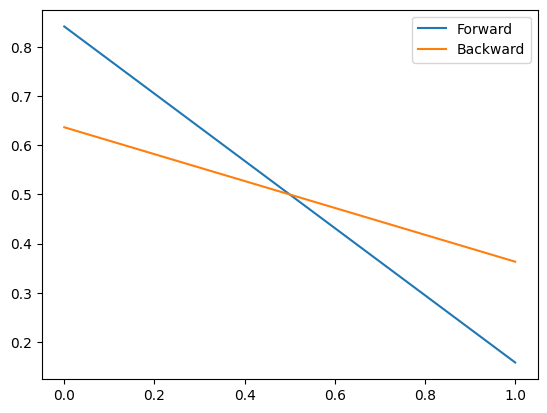

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

T = np.array([[0.7, 0.3], [0.3, 0.7]])
O = np.array([[0.9, 0.1], [0.1, 0.9]])
H = 3
obs = [0, 1, 0]

def forward(obs):
    f = np.array([0.5, 0.5])
    for x in obs:
        f = O[:, x] * (T.T @ f)
        f = f / (f[0] + f[1])
    return f

def backward(obs):
    b = np.array([1.0, 1.0])
    for x in obs[::-1]:
        b = T @ (O[:, x] * b)
        b = b / (b[0] + b[1])
    return b

f = forward(obs)
b = backward(obs)
print("Forward:", f)
print("Backward:", b)

plt.plot(f, label="Forward")
plt.plot(b, label="Backward")
plt.legend()
plt.show()

observation: [1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0]
In current Day | Smoothed P(Rainy) | Not Rainy | Error
------------------------------------------------------------
          4 |            1 | 0.8964 | 0.1036 | 0.00e+00
          5 |            2 | 0.9357 | 0.0643 | 1.39e-17
          6 |            3 | 0.9422 | 0.0578 | 2.22e-16
          7 |            4 | 0.9433 | 0.0567 | 4.58e-16
          8 |            5 | 0.9435 | 0.0565 | 2.73e-15
          9 |            6 | 0.9403 | 0.0597 | 1.65e-14
         10 |            7 | 0.9259 | 0.0741 | 1.00e-13
         11 |            8 | 0.8295 | 0.1705 | 6.09e-13
         12 |            9 | 0.2577 | 0.7423 | 3.70e-12
         13 |           10 | 0.6049 | 0.3951 | 1.39e-11
         14 |           11 | 0.1966 | 0.8034 | 4.27e-11
         15 |           12 | 0.5536 | 0.4464 | 1.89e-10
         16 |           13 | 0.0969 | 0.9031 | 5.66e-10
         17 |           14 | 0.1193 | 0.8807 | 2.54e-09
         18 |           15

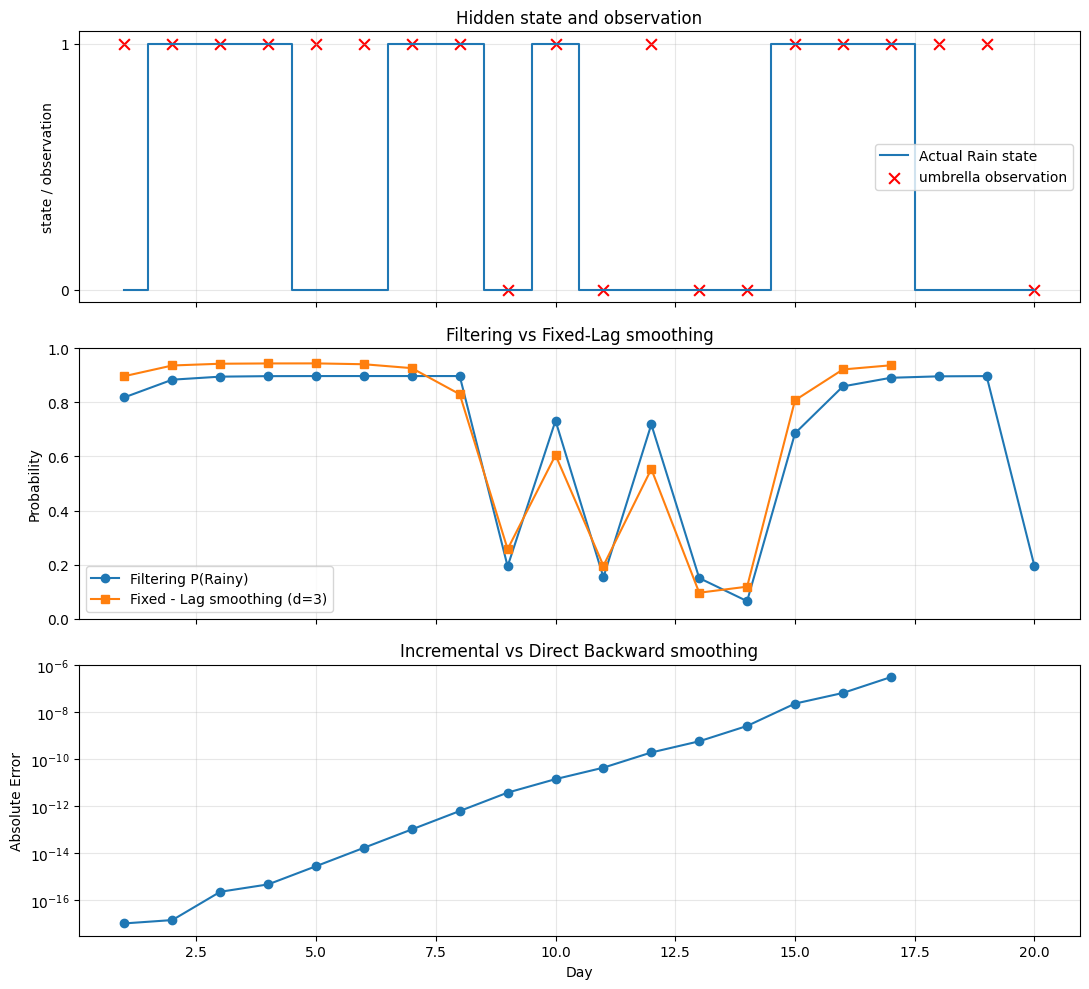

In [2]:
import numpy as np
import matplotlib.pyplot as plt

T = np.array([[.7,.3],[.3,.7]])
O = {1:np.diag([.9,.2]), 0:np.diag([.1,.8])}
N,d = 20,3
r = np.random.default_rng(12)

h,o = [],[]
s = r.choice(2,p=[.5,.5])

for i in range(N):
    s = r.choice(2,p=T[s])
    h.append(s)
    o.append(int(r.random()<[.9,.2][s]))

print("observation:",o)

def step(F,e):
    F = O[e] @ T.T @ F
    return F/F.sum()

F = np.array([.5,.5])
filtered = []

for e in o:
    F = step(F,e)
    filtered.append(F.copy())

filtered = np.array(filtered)

def back(k,t):
    b = np.ones(2)
    for i in range(t-1,k-1,-1):
        b = T @ O[o[i]] @ b
    return b

F,k,t = filtered[0].copy(),1,4
B = np.eye(2)

for i in range(k,t):
    B = B @ T @ O[o[i]]

smoothed = np.full((N,2),np.nan)
errors = []

print("In current Day | Smoothed P(Rainy) | Not Rainy | Error")
print("-"*60)

while True:
    S = F*(B @ np.ones(2))
    S /= S.sum()
    smoothed[k-1] = S

    D = F*back(k,t)
    D /= D.sum()
    errors.append(np.max(np.abs(S-D)))

    print(f"{t:11} | {k:12} | {S[0]:.4f} | {S[1]:.4f} | {errors[-1]:.2e}")

    if t == N: break

    B = np.linalg.solve(O[o[k]],np.linalg.solve(T,B)) @ T @ O[o[t]]
    F = step(F,o[k])
    k,t = k+1,t+1

print("\nMaximum verification error:",max(errors))

days = np.arange(1,N+1)
v = ~np.isnan(smoothed[:,0])

fig,ax = plt.subplots(3,1,figsize=(11,10),sharex=True)

ax[0].step(days,1-np.array(h),where="mid",label="Actual Rain state")
ax[0].scatter(days,o,marker='x',color="red",s=60,label="umbrella observation")
ax[0].set_ylabel("state / observation")
ax[0].set_title("Hidden state and observation")
ax[0].set_yticks([0,1])
ax[0].legend()
ax[0].grid(True,alpha=.3)

ax[1].plot(days,filtered[:,0],"o-",label="Filtering P(Rainy)")
ax[1].plot(days[v],smoothed[v,0],"s-",label=f"Fixed - Lag smoothing (d={d})")
ax[1].set_ylabel("Probability")
ax[1].set_title("Filtering vs Fixed-Lag smoothing")
ax[1].set_ylim(0,1)
ax[1].legend()
ax[1].grid(True,alpha=.3)

ax[2].semilogy(days[v],np.maximum(errors,1e-17),"o-")
ax[2].set_xlabel("Day")
ax[2].set_ylabel("Absolute Error")
ax[2].set_title("Incremental vs Direct Backward smoothing")
ax[2].grid(True,alpha=.3)

plt.tight_layout()
plt.savefig("HMM_fixed_Lag_smoothing.png",dpi=300)
plt.show()

# Quick Revision and Viva

## Search algorithm comparison

| Algorithm | Main data structure / priority | Main idea |
|---|---|---|
| BFS | FIFO queue | Explores level by level |
| DFS | LIFO stack | Explores deeply before backtracking |
| UCS | Lowest accumulated cost `g` | Selects the cheapest path so far |
| A* | Lowest `f = g + h` | Combines path cost and heuristic |

## Probability and AI terms

- **PMF:** Probability Mass Function; gives probabilities for discrete outcomes.
- **PDF:** Probability Density Function; describes density for continuous variables.
- **Prior:** Probability before observing new evidence.
- **Likelihood:** Probability of evidence under a particular hypothesis or state.
- **Posterior:** Updated probability after considering evidence.
- **CPD/CPT:** Conditional Probability Distribution/Table.
- **Heuristic:** An estimate used by informed search, such as A*.
- **HMM:** A model with hidden states, transition probabilities, observations and emission probabilities.

## Short viva questions

1. **What is BFS?** A graph search method that explores level by level using a FIFO queue.
2. **What is DFS?** A graph search method that explores deeply using a LIFO stack.
3. **Which search selects the lowest path cost?** Uniform Cost Search.
4. **What is the A* formula?** `f(n) = g(n) + h(n)`.
5. **What is a Bernoulli trial?** One experiment with two possible outcomes, often success and failure.
6. **Difference between Bernoulli and Binomial?** Bernoulli models one trial; Binomial models the number of successes in `n` independent trials.
7. **What is a continuous uniform distribution?** A distribution with constant density over a specified interval.
8. **What does a Bayesian network represent?** Probabilistic relationships using a directed acyclic graph and conditional probability tables.
9. **What is enumeration in Bayesian inference?** Summing joint probabilities over assignments consistent with the evidence.
10. **What does the Forward algorithm do?** Processes HMM observations from left to right.
11. **What does the Backward algorithm do?** Processes HMM observations from right to left.

## Exam preparation tip

For every program, practise four things:
1. State the purpose of the algorithm, distribution or model.
2. Explain the important variables.
3. Describe the main loop, data structure or formula.
4. Interpret the output or graph.